# EXP-3: Fine-tune ConvNeXt-Tiny — Scheduler tốt hơn (Cosine Annealing)

Notebook này thực hiện **EXP-3** trong pipeline fine-tuning ConvNeXt-Tiny:

```
BASELINE → EXP-1 → EXP-2 → EXP-3 (Scheduler tốt hơn) → EXP-4 → EXP-5 → EXP-6 → FINAL
```

**Vì sao đổi scheduler?** Ở EXP-1 và EXP-2, `val_loss` tăng dần đều qua các epoch trong khi `val_f1` gần như đi ngang và `val_roc_auc` giảm dần — dấu hiệu model bắt đầu overconfident/overfit nhẹ. `ReduceLROnPlateau` chỉ giảm LR **sau khi** phát hiện metric chững lại (có độ trễ `patience`), nên LR vẫn giữ cao trong lúc model đã bắt đầu overfit.

**Thay đổi duy nhất so với EXP-2:** scheduler đổi từ `ReduceLROnPlateau` sang **`CosineAnnealingLR`** — LR giảm mượt và liên tục theo hình cosine từ giá trị ban đầu xuống gần 0 trong suốt quá trình train, không phụ thuộc vào việc phát hiện plateau. Điều này giúp kiềm chế overfitting ở các epoch cuối một cách chủ động hơn.

Tất cả các điều kiện khác (4 nhóm discriminative LR, augmentation, loss, batch size, epochs...) **giữ nguyên** như EXP-2.

**Bổ sung:** notebook này hiển thị và log tường minh **Accuracy** bên cạnh F1/ROC-AUC/Loss, vì mục tiêu cuối cùng của dự án là **Accuracy ≥ 95%**.

**Nguồn checkpoint:** đọc `best_tracker.json` để lấy checkpoint tốt nhất tính đến hiện tại (dự kiến là EXP-2, do F1 cao nhất).

In [1]:
!pip install -q torch torchvision torchaudio
!pip install -q pandas numpy matplotlib seaborn scikit-learn tqdm


In [2]:
import os
import gc
import json
import time
import copy
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("All libraries imported successfully.")
print("PyTorch:", torch.__version__)


All libraries imported successfully.
PyTorch: 2.11.0+cu128


In [3]:
# =========================
# Reproducibility
# =========================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# =========================
# Device
# =========================

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")


print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        f"GPU Memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
    )


# =========================
# CUDA optimization
# =========================

if device.type == "cuda":
    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("CUDA optimization configured.")


Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB
CUDA optimization configured.


In [5]:
from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


In [6]:
print(os.listdir("/content/drive/MyDrive")[:30])


['7eb83c0ff94e42fbb1be86c1c38cbd18.mov', 'Cát Bà', 'IMG_6950.HEIC', 'IMG_6949.HEIC', 'bai tap c32.docx', 'Colab Notebooks', 'face_frames.zip', 'FaceForensics_Experiments']


In [7]:
# =========================
# Google Drive
# =========================

DRIVE_ROOT = "/content/drive/MyDrive"

ZIP_NAME = "face_frames.zip"

ZIP_PATH = os.path.join(
    DRIVE_ROOT,
    ZIP_NAME
)


# =========================
# Local Colab
# =========================

EXTRACT_DIR = "/content/faceforensics"


# =========================
# Experiment output (dùng chung với BASELINE / EXP-1 / EXP-2)
# =========================

EXPERIMENT_DIR = os.path.join(
    DRIVE_ROOT,
    "FaceForensics_Experiments"
)

MODEL_COMPARISON_CSV = os.path.join(
    EXPERIMENT_DIR,
    "results",
    "model_comparison.csv"
)


# =========================
# Thư mục pipeline fine-tune ConvNeXt-Tiny
# (dùng chung cho EXP-1 -> EXP-6 -> FINAL)
# =========================

FINETUNE_DIR = os.path.join(
    EXPERIMENT_DIR,
    "finetune_convnext_tiny"
)

FT_CHECKPOINT_DIR = os.path.join(
    FINETUNE_DIR,
    "checkpoints"
)

FT_HISTORY_DIR = os.path.join(
    FINETUNE_DIR,
    "histories"
)

FT_RESULT_DIR = os.path.join(
    FINETUNE_DIR,
    "results"
)

BEST_TRACKER_PATH = os.path.join(
    FINETUNE_DIR,
    "best_tracker.json"
)

EXPERIMENTS_LOG_PATH = os.path.join(
    FT_RESULT_DIR,
    "experiments_log.csv"
)


for folder in [
    EXPERIMENT_DIR,
    FINETUNE_DIR,
    FT_CHECKPOINT_DIR,
    FT_HISTORY_DIR,
    FT_RESULT_DIR
]:
    os.makedirs(folder, exist_ok=True)


print("ZIP:", ZIP_PATH)
print("Extract:", EXTRACT_DIR)
print("Finetune dir:", FINETUNE_DIR)
print("Best tracker:", BEST_TRACKER_PATH)


ZIP: /content/drive/MyDrive/face_frames.zip
Extract: /content/faceforensics
Finetune dir: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny
Best tracker: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/best_tracker.json


In [8]:
# =========================
# Đọc best_tracker.json
# =========================

def init_best_tracker():
    """Fallback: nếu chưa từng chạy EXP nào, khởi tạo từ BASELINE (convnext_tiny)."""

    if os.path.exists(BEST_TRACKER_PATH):
        with open(BEST_TRACKER_PATH, "r") as f:
            return json.load(f)

    if not os.path.exists(MODEL_COMPARISON_CSV):
        raise FileNotFoundError(
            f"Không tìm thấy {MODEL_COMPARISON_CSV} và cũng chưa có "
            f"best_tracker.json. Hãy chạy Comparation_3_model.ipynb "
            f"và/hoặc các EXP trước đó."
        )

    comparison_df = pd.read_csv(MODEL_COMPARISON_CSV)

    baseline_row = comparison_df[
        comparison_df["model"] == "convnext_tiny"
    ].iloc[0]

    tracker = {
        "source_exp": "BASELINE",
        "checkpoint": baseline_row["checkpoint"],
        "best_val_f1": float(baseline_row["best_val_f1"]),
        "best_val_roc_auc": float(baseline_row["best_val_roc_auc"]),
        "best_val_accuracy": None,
    }

    with open(BEST_TRACKER_PATH, "w") as f:
        json.dump(tracker, f, indent=2)

    return tracker


best_tracker = init_best_tracker()

# Tương thích ngược: nếu tracker cũ (từ EXP-1/EXP-2) chưa có accuracy
best_tracker.setdefault("best_val_accuracy", None)

CURRENT_BEST_CHECKPOINT = best_tracker["checkpoint"]

print("Best checkpoint hiện tại được lấy từ:", best_tracker["source_exp"])
print("Checkpoint path :", CURRENT_BEST_CHECKPOINT)
print("Best val_f1     :", best_tracker["best_val_f1"])
print("Best val_roc_auc:", best_tracker["best_val_roc_auc"])
print("Best val_accuracy:", best_tracker["best_val_accuracy"])

if not os.path.exists(CURRENT_BEST_CHECKPOINT):
    raise FileNotFoundError(
        f"Không tìm thấy checkpoint: {CURRENT_BEST_CHECKPOINT}\n"
        "Hãy kiểm tra lại đường dẫn trên Google Drive."
    )


Best checkpoint hiện tại được lấy từ: exp2_unfreeze_discriminative_lr
Checkpoint path : /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp2_unfreeze_discriminative_lr_best.pth
Best val_f1     : 0.9253681946053285
Best val_roc_auc: 0.8085869536714719
Best val_accuracy: None


In [9]:
if os.path.exists(ZIP_PATH):
    size_gb = os.path.getsize(ZIP_PATH) / 1024**3
    print(f"Found ZIP: {ZIP_PATH}")
    print(f"ZIP size: {size_gb:.2f} GB")
else:
    raise FileNotFoundError(
        f"Không tìm thấy {ZIP_PATH}\n"
        "Hãy kiểm tra lại tên file hoặc vị trí trên Google Drive."
    )


Found ZIP: /content/drive/MyDrive/face_frames.zip
ZIP size: 0.93 GB


In [10]:
if os.path.exists(EXTRACT_DIR):
    print("Extract directory already exists.")
    print("Skip extraction.")

else:

    os.makedirs(EXTRACT_DIR, exist_ok=True)

    print("Extracting dataset...")
    print("This may take some time...")

    start_time = time.time()

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    elapsed = time.time() - start_time

    print(f"Extraction completed in {elapsed:.1f} seconds.")


Extracting dataset...
This may take some time...
Extraction completed in 28.8 seconds.


In [11]:
print(os.listdir(EXTRACT_DIR))


['face_frames']


In [12]:
def find_dataset_root(base_dir):

    candidates = []

    for root, dirs, files in os.walk(base_dir):

        dir_names = {d.lower() for d in dirs}

        if "train" in dir_names and "val" in dir_names and "test" in dir_names:
            candidates.append(root)

    if len(candidates) == 0:
        raise FileNotFoundError("Không tìm thấy thư mục chứa train/val/test.")

    return candidates[0]


DATA_DIR = find_dataset_root(EXTRACT_DIR)

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR = os.path.join(DATA_DIR, "val")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("DATA_DIR : ", DATA_DIR)
print("TRAIN_DIR:", TRAIN_DIR)
print("VAL_DIR  :", VAL_DIR)
print("TEST_DIR :", TEST_DIR)


DATA_DIR :  /content/faceforensics/face_frames
TRAIN_DIR: /content/faceforensics/face_frames/train
VAL_DIR  : /content/faceforensics/face_frames/val
TEST_DIR : /content/faceforensics/face_frames/test


In [13]:
print("\nTrain:")
print(os.listdir(TRAIN_DIR))

print("\nValidation:")
print(os.listdir(VAL_DIR))



Train:
['REAL', 'FAKE']

Validation:
['REAL', 'FAKE']


In [14]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def count_images(folder):

    count = 0

    for path in Path(folder).rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            count += 1

    return count


def count_class_images(split_dir):

    result = {}

    for class_dir in Path(split_dir).iterdir():
        if not class_dir.is_dir():
            continue
        class_name = class_dir.name.upper()
        result[class_name] = count_images(class_dir)

    return result


train_counts = count_class_images(TRAIN_DIR)
val_counts = count_class_images(VAL_DIR)

print("========== TRAIN ==========")
for cls, count in train_counts.items():
    print(f"{cls}: {count:,}")

print("\n========== VALIDATION ==========")
for cls, count in val_counts.items():
    print(f"{cls}: {count:,}")

print("\nTotal TRAIN:", f"{sum(train_counts.values()):,}")
print("Total VALIDATION:", f"{sum(val_counts.values()):,}")


========== TRAIN ==========
REAL: 7,898
FAKE: 46,448

========== VALIDATION ==========
REAL: 1,020
FAKE: 5,982

Total TRAIN: 54,346
Total VALIDATION: 7,002


In [15]:
# =========================
# Image
# =========================

IMG_SIZE = 224


# =========================
# Training
# =========================
#
# EXP-3: "Scheduler tot hon"
#   - Giu nguyen 4 nhom discriminative LR tu EXP-2.
#   - Doi scheduler: ReduceLROnPlateau -> CosineAnnealingLR (giam LR
#     muot lien tuc, khong doi phat hien plateau).
#
# Toan bo tham so khac (augmentation, loss, batch size, epochs...)
# giu NGUYEN nhu EXP-2.

BATCH_SIZE = 64
EPOCHS = 10

WEIGHT_DECAY = 1e-4

# ---- Discriminative learning rates (giữ nguyên như EXP-2) ----
LR_STEM_STAGE1   = 1e-6   # features[0:2]  (stem + stage 1)
LR_STAGE2        = 3e-6   # features[2:4]  (downsample + stage 2)
LR_STAGE3        = 1e-5   # features[4:6]  (downsample + stage 3)
LR_STAGE4_HEAD   = 3e-5   # features[6:8] + classifier (downsample + stage4 + head)

LEARNING_RATE = LR_STAGE4_HEAD  # dùng để log/so sánh chung

# ---- Cosine Annealing scheduler ----
COSINE_T_MAX = EPOCHS     # 1 chu kỳ cosine trọn vẹn trong suốt quá trình train
COSINE_ETA_MIN_RATIO = 0.01  # LR cuối cùng ~ 1% LR ban đầu của mỗi nhóm


# =========================
# DataLoader
# =========================

NUM_WORKERS = 4
PIN_MEMORY = (device.type == "cuda")
PERSISTENT_WORKERS = (NUM_WORKERS > 0)
PREFETCH_FACTOR = 2


# =========================
# Mixed Precision
# =========================

USE_AMP = (device.type == "cuda")


# =========================
# Classes
# =========================

CLASS_TO_LABEL = {"REAL": 0, "FAKE": 1}
LABEL_TO_CLASS = {0: "REAL", 1: "FAKE"}


# =========================
# Experiment identity
# =========================

MODEL_NAME = "convnext_tiny"
EXP_NAME = "exp3_cosine_scheduler"
EXP_DESCRIPTION = (
    "Giu nguyen discriminative LR (4 nhom) tu EXP-2, doi scheduler "
    "ReduceLROnPlateau -> CosineAnnealingLR de kiem che val_loss tang "
    "dan / AUC giam da thay o EXP-1, EXP-2"
)


print("IMG_SIZE:", IMG_SIZE)
print("BATCH_SIZE:", BATCH_SIZE)
print("EPOCHS:", EPOCHS)
print("WEIGHT_DECAY:", WEIGHT_DECAY)
print("LR groups:")
print("  stem+stage1 :", LR_STEM_STAGE1)
print("  stage2      :", LR_STAGE2)
print("  stage3      :", LR_STAGE3)
print("  stage4+head :", LR_STAGE4_HEAD)
print("Cosine T_max:", COSINE_T_MAX)
print("AMP:", USE_AMP)
print("EXP_NAME:", EXP_NAME)


IMG_SIZE: 224
BATCH_SIZE: 64
EPOCHS: 10
WEIGHT_DECAY: 0.0001
LR groups:
  stem+stage1 : 1e-06
  stage2      : 3e-06
  stage3      : 1e-05
  stage4+head : 3e-05
Cosine T_max: 10
AMP: True
EXP_NAME: exp3_cosine_scheduler


In [16]:
train_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


print("Transforms ready (unchanged from EXP-2).")


Transforms ready (unchanged from EXP-2).


In [17]:
def create_dataframe(split_dir):

    records = []
    split_path = Path(split_dir)

    for class_dir in split_path.iterdir():

        if not class_dir.is_dir():
            continue

        class_name = class_dir.name.upper()

        if class_name not in CLASS_TO_LABEL:
            print(f"Warning: ignored class {class_name}")
            continue

        label = CLASS_TO_LABEL[class_name]

        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "image_path": str(image_path),
                    "label": label,
                    "class_name": class_name
                })

    return pd.DataFrame(records)


train_df = create_dataframe(TRAIN_DIR)
val_df = create_dataframe(VAL_DIR)

print("TRAIN:", f"{len(train_df):,}")
print("VAL:", f"{len(val_df):,}")


TRAIN: 54,346
VAL: 7,002


In [18]:
print("\nTRAIN")
print(train_df["class_name"].value_counts())

print("\nVAL")
print(val_df["class_name"].value_counts())



TRAIN
class_name
FAKE    46448
REAL     7898
Name: count, dtype: int64

VAL
class_name
FAKE    5982
REAL    1020
Name: count, dtype: int64


In [19]:
class FaceForensicsDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]
        image_path = row["image_path"]
        label = int(row["label"])

        try:
            image = Image.open(image_path).convert("RGB")
        except Exception as e:
            print(f"\nError loading:\n{image_path}")
            raise e

        if self.transform is not None:
            image = self.transform(image)

        return image, label


In [20]:
train_dataset = FaceForensicsDataset(train_df, transform=train_transform)
val_dataset = FaceForensicsDataset(val_df, transform=val_transform)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None
)


print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Train batches: 850
Val batches: 110


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [21]:
def create_model(model_name):

    if model_name == "convnext_tiny":

        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)

        in_features = model.classifier[-1].in_features

        model.classifier[-1] = nn.Linear(in_features, 2)

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model


def load_finetune_weights(model, checkpoint_path):
    """Load trọng số từ best checkpoint trước đó."""

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False  # checkpoint tu train, tin tuong duoc (PyTorch 2.6+ mac dinh weights_only=True)
    )

    state_dict = checkpoint.get("model_state_dict", checkpoint)

    model.load_state_dict(state_dict)

    print(f"Loaded weights from: {checkpoint_path}")

    if "metrics" in checkpoint:
        print("  Source metrics:", checkpoint["metrics"])

    return model


def unfreeze_all(model):

    for param in model.parameters():
        param.requires_grad = True

    return model


In [22]:
model = create_model(MODEL_NAME)

model = load_finetune_weights(model, CURRENT_BEST_CHECKPOINT)

model = unfreeze_all(model)

model = model.to(device)

if device.type == "cuda":
    model = model.to(memory_format=torch.channels_last)


total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(
    f"{MODEL_NAME:20s}"
    f" | Params: {total_params / 1e6:.2f}M"
    f" | Trainable: {trainable_params / 1e6:.2f}M"
)

assert total_params == trainable_params, "Vẫn còn tham số bị đóng băng!"
print("✓ Toàn bộ tham số đã unfreeze (trainable = total).")


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 176MB/s] 


Loaded weights from: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp2_unfreeze_discriminative_lr_best.pth
  Source metrics: {'loss': 0.8091342332032307, 'accuracy': 0.8711796629534418, 'precision': 0.9161205766710354, 'recall': 0.9348044132397192, 'f1': 0.9253681946053285, 'roc_auc': np.float64(0.8085869536714719)}
convnext_tiny        | Params: 27.82M | Trainable: 27.82M
✓ Toàn bộ tham số đã unfreeze (trainable = total).


In [23]:
class_counts = train_df["label"].value_counts().sort_index()

print("Class counts:")
for label, count in class_counts.items():
    print(LABEL_TO_CLASS[label], ":", f"{count:,}")

total_samples = len(train_df)
num_classes = 2

class_weights = []
for label in range(num_classes):
    count = class_counts[label]
    weight = total_samples / (num_classes * count)
    class_weights.append(weight)

class_weights = torch.tensor(class_weights, dtype=torch.float32, device=device)

print("\nClass weights:")
for label, weight in enumerate(class_weights):
    print(LABEL_TO_CLASS[label], ":", f"{weight.item():.4f}")


Class counts:
REAL : 7,898
FAKE : 46,448

Class weights:
REAL : 3.4405
FAKE : 0.5850


In [24]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

print(criterion)


CrossEntropyLoss()


In [25]:
def build_discriminative_param_groups(model):
    """Giữ nguyên cách chia nhóm như EXP-2 (4 nhóm theo độ sâu)."""

    features = model.features

    group_stem_stage1 = list(features[0].parameters()) + list(features[1].parameters())
    group_stage2 = list(features[2].parameters()) + list(features[3].parameters())
    group_stage3 = list(features[4].parameters()) + list(features[5].parameters())

    group_stage4_head = (
        list(features[6].parameters())
        + list(features[7].parameters())
        + list(model.avgpool.parameters())
        + list(model.classifier.parameters())
    )

    n_grouped = sum(
        p.numel()
        for g in [group_stem_stage1, group_stage2, group_stage3, group_stage4_head]
        for p in g
    )
    n_total = sum(p.numel() for p in model.parameters())

    assert n_grouped == n_total, (
        f"Param groups không khớp tổng số tham số! "
        f"grouped={n_grouped:,} vs total={n_total:,}."
    )

    param_groups = [
        {"params": group_stem_stage1, "lr": LR_STEM_STAGE1, "name": "stem+stage1"},
        {"params": group_stage2,      "lr": LR_STAGE2,      "name": "stage2"},
        {"params": group_stage3,      "lr": LR_STAGE3,      "name": "stage3"},
        {"params": group_stage4_head, "lr": LR_STAGE4_HEAD, "name": "stage4+head"},
    ]

    print("Discriminative LR param groups:")
    for g in param_groups:
        n_params = sum(p.numel() for p in g["params"])
        print(f"  {g['name']:15s} | LR={g['lr']:.1e} | Params={n_params/1e6:.2f}M")

    return param_groups


def create_optimizer(model):

    param_groups = build_discriminative_param_groups(model)

    return torch.optim.AdamW(
        param_groups,
        weight_decay=WEIGHT_DECAY
    )


In [26]:
def create_scheduler(optimizer):
    """
    EXP-3: CosineAnnealingLR thay cho ReduceLROnPlateau.

    LR của MỖI param group giảm theo đường cosine riêng, từ giá trị ban
    đầu của nhóm đó xuống eta_min (~1% giá trị ban đầu), trong đúng
    COSINE_T_MAX epoch — không phụ thuộc việc phát hiện plateau nên
    không có độ trễ, giúp kiềm chế overfitting chủ động hơn ở các
    epoch cuối.
    """

    # eta_min tính riêng cho từng group theo tỉ lệ COSINE_ETA_MIN_RATIO
    eta_mins = [
        group["lr"] * COSINE_ETA_MIN_RATIO
        for group in optimizer.param_groups
    ]

    # torch.optim.lr_scheduler.CosineAnnealingLR chỉ nhận 1 eta_min dùng
    # chung cho tất cả group nếu truyền số; để mỗi group có eta_min
    # riêng theo đúng tỉ lệ, dùng LambdaLR mô phỏng cosine theo tỉ lệ.
    import math

    def cosine_factor(epoch):
        # trả về hệ số nhân [ratio_min .. 1.0] theo epoch (0-indexed)
        progress = epoch / max(1, COSINE_T_MAX)
        cosine = 0.5 * (1 + math.cos(math.pi * progress))
        return COSINE_ETA_MIN_RATIO + (1 - COSINE_ETA_MIN_RATIO) * cosine

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=[cosine_factor for _ in optimizer.param_groups]
    )

    return scheduler


In [27]:
def train_one_epoch(model, loader, criterion, optimizer, scaler):

    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    progress = tqdm(loader, desc="Train", leave=False)

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if device.type == "cuda":
            images = images.contiguous(memory_format=torch.channels_last)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_f1 = f1_score(all_labels, all_preds, pos_label=1, zero_division=0)

    return epoch_loss, epoch_f1


In [28]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if device.type == "cuda":
                images = images.contiguous(memory_format=torch.channels_last)

            with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            probabilities = torch.softmax(outputs, dim=1)
            preds = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probabilities[:, 1].cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    accuracy = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, pos_label=1, zero_division=0)
    recall = recall_score(all_labels, all_preds, pos_label=1, zero_division=0)
    f1 = f1_score(all_labels, all_preds, pos_label=1, zero_division=0)
    auc = roc_auc_score(all_labels, all_probs)

    return {
        "loss": epoch_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc
    }


In [29]:
def save_checkpoint(model, optimizer, scheduler, scaler, epoch, metrics, best_f1):

    checkpoint_path = os.path.join(
        FT_CHECKPOINT_DIR,
        f"{MODEL_NAME}_{EXP_NAME}_best.pth"
    )

    checkpoint = {

        "model_name": MODEL_NAME,
        "exp_name": EXP_NAME,
        "finetuned_from": CURRENT_BEST_CHECKPOINT,

        "epoch": epoch,

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict() if USE_AMP else None,

        "best_f1": best_f1,
        "metrics": metrics,

        "config": {
            "img_size": IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
            "weight_decay": WEIGHT_DECAY,
            "lr_stem_stage1": LR_STEM_STAGE1,
            "lr_stage2": LR_STAGE2,
            "lr_stage3": LR_STAGE3,
            "lr_stage4_head": LR_STAGE4_HEAD,
            "scheduler": "CosineAnnealingLR (custom lambda)",
            "cosine_t_max": COSINE_T_MAX,
            "cosine_eta_min_ratio": COSINE_ETA_MIN_RATIO,
            "seed": SEED
        }
    }

    torch.save(checkpoint, checkpoint_path)

    return checkpoint_path


In [30]:
def train_model():

    print("\n")
    print("=" * 70)
    print(f"START FINE-TUNE: {MODEL_NAME} | {EXP_NAME}")
    print(f"Description: {EXP_DESCRIPTION}")
    print(f"Starting from: {CURRENT_BEST_CHECKPOINT}")
    print("=" * 70)

    optimizer = create_optimizer(model)
    scheduler = create_scheduler(optimizer)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = []
    best_f1 = -1.0
    best_auc = -1.0
    best_accuracy = -1.0
    best_epoch = -1

    total_start = time.time()

    for epoch in range(EPOCHS):

        epoch_start = time.time()

        print(f"\nEpoch {epoch + 1}/{EPOCHS}")

        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        val_metrics = validate(model, val_loader, criterion)

        # CosineAnnealingLR (LambdaLR) step KHÔNG nhận metric, chạy mỗi epoch
        scheduler.step()

        current_lrs = [g["lr"] for g in optimizer.param_groups]

        epoch_time = time.time() - epoch_start

        row = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_f1": train_f1,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_precision": val_metrics["precision"],
            "val_recall": val_metrics["recall"],
            "val_f1": val_metrics["f1"],
            "val_roc_auc": val_metrics["roc_auc"],
            "lr_stem_stage1": current_lrs[0],
            "lr_stage2": current_lrs[1],
            "lr_stage3": current_lrs[2],
            "lr_stage4_head": current_lrs[3],
            "epoch_time_sec": epoch_time
        }

        history.append(row)

        print(f"Train Loss : {train_loss:.4f}")
        print(f"Train F1   : {train_f1:.4f}")
        print(f"Val Loss   : {val_metrics['loss']:.4f}")
        print(f"Val Acc    : {val_metrics['accuracy']:.4f}")
        print(f"Val F1     : {val_metrics['f1']:.4f}")
        print(f"Val ROC-AUC: {val_metrics['roc_auc']:.4f}")
        print(f"LRs (stem->head): {[f'{lr:.1e}' for lr in current_lrs]}")
        print(f"Epoch time : {epoch_time:.1f}s")

        is_better = (
            val_metrics["f1"] > best_f1
            or (val_metrics["f1"] == best_f1 and val_metrics["roc_auc"] > best_auc)
        )

        if is_better:

            best_f1 = val_metrics["f1"]
            best_auc = val_metrics["roc_auc"]
            best_accuracy = val_metrics["accuracy"]
            best_epoch = epoch + 1

            checkpoint_path = save_checkpoint(
                model, optimizer, scheduler, scaler, epoch + 1, val_metrics, best_f1
            )

            print(f"✓ BEST MODEL (EXP-3) SAVED")
            print(f"  F1: {best_f1:.4f}")
            print(f"  AUC: {best_auc:.4f}")
            print(f"  Accuracy: {best_accuracy:.4f}")
            print(f"  Path: {checkpoint_path}")

    total_time = time.time() - total_start

    history_df = pd.DataFrame(history)

    history_path = os.path.join(
        FT_HISTORY_DIR,
        f"{MODEL_NAME}_{EXP_NAME}_history.csv"
    )

    history_df.to_csv(history_path, index=False)

    summary = {
        "exp_name": EXP_NAME,
        "description": EXP_DESCRIPTION,
        "model": MODEL_NAME,
        "finetuned_from": CURRENT_BEST_CHECKPOINT,
        "learning_rate": LEARNING_RATE,
        "best_epoch": best_epoch,
        "best_val_f1": best_f1,
        "best_val_roc_auc": best_auc,
        "best_val_accuracy": best_accuracy,
        "total_training_time_sec": total_time,
        "average_epoch_time_sec": history_df["epoch_time_sec"].mean(),
        "checkpoint": os.path.join(
            FT_CHECKPOINT_DIR, f"{MODEL_NAME}_{EXP_NAME}_best.pth"
        ),
        "history": history_path
    }

    print("\n")
    print("=" * 70)
    print(f"FINISHED: {EXP_NAME}")
    print("=" * 70)
    print(f"Best Epoch   : {best_epoch}")
    print(f"Best F1      : {best_f1:.4f}")
    print(f"Best AUC     : {best_auc:.4f}")
    print(f"Best Accuracy: {best_accuracy:.4f}  (mục tiêu >= 0.95)")
    print(f"Avg epoch    : {summary['average_epoch_time_sec']:.1f}s")
    print(f"Total time   : {total_time / 60:.2f} min")

    return summary, history_df


In [31]:
exp3_summary, exp3_history = train_model()




START FINE-TUNE: convnext_tiny | exp3_cosine_scheduler
Description: Giu nguyen discriminative LR (4 nhom) tu EXP-2, doi scheduler ReduceLROnPlateau -> CosineAnnealingLR de kiem che val_loss tang dan / AUC giam da thay o EXP-1, EXP-2
Starting from: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp2_unfreeze_discriminative_lr_best.pth
Discriminative LR param groups:
  stem+stage1     | LR=1.0e-06 | Params=0.24M
  stage2          | LR=3.0e-06 | Params=0.99M
  stage3          | LR=1.0e-05 | Params=11.11M
  stage4+head     | LR=3.0e-05 | Params=15.47M

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train:   0%|          | 0/850 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Train Loss : 0.0359
Train F1   : 0.9915
Val Loss   : 0.9750
Val Acc    : 0.8608
Val F1     : 0.9178
Val ROC-AUC: 0.8011
LRs (stem->head): ['9.8e-07', '2.9e-06', '9.8e-06', '2.9e-05']
Epoch time : 490.2s
✓ BEST MODEL (EXP-3) SAVED
  F1: 0.9178
  AUC: 0.8011
  Accuracy: 0.8608
  Path: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth

Epoch 2/10


...

Train Loss : 0.0532
Train F1   : 0.9861
Val Loss   : 0.8893
Val Acc    : 0.8670
Val F1     : 0.9227
Val ROC-AUC: 0.7966
LRs (stem->head): ['1.0e-07', '3.1e-07', '1.0e-06', '3.1e-06']
Epoch time : 429.3s

Epoch 9/10


Train:   0%|          | 0/850 [00:00<?, ?it/s]

Train Loss : 0.0734
Train F1   : 0.9814
Val Loss   : 0.7891
Val Acc    : 0.8608
Val F1     : 0.9178
Val ROC-AUC: 0.8256
LRs (stem->head): ['3.4e-08', '1.0e-07', '3.4e-07', '1.0e-06']
Epoch time : 429.4s

Epoch 10/10


Train:   0%|          | 0/850 [00:00<?, ?it/s]

Train Loss : 0.0760
Train F1   : 0.9797
Val Loss   : 0.7733
Val Acc    : 0.8615
Val F1     : 0.9183
Val ROC-AUC: 0.8261
LRs (stem->head): ['1.0e-08', '3.0e-08', '1.0e-07', '3.0e-07']
Epoch time : 433.4s


FINISHED: exp3_cosine_scheduler
Best Epoch   : 2
Best F1      : 0.9260
Best AUC     : 0.7684
Best Accuracy: 0.8720  (mục tiêu >= 0.95)
Avg epoch    : 437.8s
Total time   : 73.04 min


In [32]:
# =========================
# So sánh EXP-3 với best hiện tại, cập nhật best_tracker.json NẾU tốt hơn
# =========================

is_new_best = (
    exp3_summary["best_val_f1"] > best_tracker["best_val_f1"]
    or (
        exp3_summary["best_val_f1"] == best_tracker["best_val_f1"]
        and exp3_summary["best_val_roc_auc"] > best_tracker["best_val_roc_auc"]
    )
)

print(f"Previous best ({best_tracker['source_exp']}):")
print(f"  val_f1      = {best_tracker['best_val_f1']:.4f}")
print(f"  val_roc_auc = {best_tracker['best_val_roc_auc']:.4f}")
print(f"  val_accuracy= {best_tracker['best_val_accuracy']}")

print(f"\nEXP-3 result:")
print(f"  val_f1      = {exp3_summary['best_val_f1']:.4f}")
print(f"  val_roc_auc = {exp3_summary['best_val_roc_auc']:.4f}")
print(f"  val_accuracy= {exp3_summary['best_val_accuracy']:.4f}")

if is_new_best:

    best_tracker = {
        "source_exp": EXP_NAME,
        "checkpoint": exp3_summary["checkpoint"],
        "best_val_f1": exp3_summary["best_val_f1"],
        "best_val_roc_auc": exp3_summary["best_val_roc_auc"],
        "best_val_accuracy": exp3_summary["best_val_accuracy"],
    }

    with open(BEST_TRACKER_PATH, "w") as f:
        json.dump(best_tracker, f, indent=2)

    print(
        f"\n✓ EXP-3 CẢI THIỆN kết quả. "
        f"best_tracker.json đã được cập nhật -> nguồn cho EXP-4 sẽ là EXP-3."
    )

else:

    print(
        f"\n✗ EXP-3 KHÔNG cải thiện so với best hiện tại "
        f"({best_tracker['source_exp']}). "
        f"best_tracker.json GIỮ NGUYÊN -> EXP-4 vẫn fine-tune từ "
        f"{best_tracker['source_exp']}, không phải từ EXP-3."
    )

gap_to_target = 0.95 - exp3_summary["best_val_accuracy"]
print(
    f"\nKhoảng cách tới mục tiêu Accuracy >= 95%: "
    f"{gap_to_target*100:.2f} điểm % (hiện tại: {exp3_summary['best_val_accuracy']*100:.2f}%)"
)


Previous best (exp2_unfreeze_discriminative_lr):
  val_f1      = 0.9254
  val_roc_auc = 0.8086
  val_accuracy= None

EXP-3 result:
  val_f1      = 0.9260
  val_roc_auc = 0.7684
  val_accuracy= 0.8720

✓ EXP-3 CẢI THIỆN kết quả. best_tracker.json đã được cập nhật -> nguồn cho EXP-4 sẽ là EXP-3.

Khoảng cách tới mục tiêu Accuracy >= 95%: 7.80 điểm % (hiện tại: 87.20%)


In [33]:
# =========================
# Ghi log vào experiments_log.csv (tổng hợp toàn bộ pipeline EXP-1..FINAL)
# =========================

log_row = pd.DataFrame([{
    "exp_name": EXP_NAME,
    "description": EXP_DESCRIPTION,
    "model": MODEL_NAME,
    "finetuned_from": CURRENT_BEST_CHECKPOINT,
    "learning_rate": LEARNING_RATE,
    "lr_stem_stage1": LR_STEM_STAGE1,
    "lr_stage2": LR_STAGE2,
    "lr_stage3": LR_STAGE3,
    "lr_stage4_head": LR_STAGE4_HEAD,
    "scheduler": "CosineAnnealingLR",
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "best_epoch": exp3_summary["best_epoch"],
    "best_val_f1": exp3_summary["best_val_f1"],
    "best_val_roc_auc": exp3_summary["best_val_roc_auc"],
    "best_val_accuracy": exp3_summary["best_val_accuracy"],
    "total_training_time_sec": exp3_summary["total_training_time_sec"],
    "checkpoint": exp3_summary["checkpoint"],
    "is_new_best": is_new_best
}])

if os.path.exists(EXPERIMENTS_LOG_PATH):
    existing_log = pd.read_csv(EXPERIMENTS_LOG_PATH)
    existing_log = existing_log[existing_log["exp_name"] != EXP_NAME]
    full_log = pd.concat([existing_log, log_row], ignore_index=True)
else:
    full_log = log_row

full_log.to_csv(EXPERIMENTS_LOG_PATH, index=False)

print("Saved:", EXPERIMENTS_LOG_PATH)
display(full_log)


Saved: /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/results/experiments_log.csv


,exp_name,description,model,finetuned_from,learning_rate,weight_decay,batch_size,epochs,best_epoch,best_val_f1,best_val_roc_auc,total_training_time_sec,checkpoint,is_new_best,lr_stem_stage1,lr_stage2,lr_stage3,lr_stage4_head,scheduler,best_val_accuracy
0,exp1_lr_low,"Fine-tune LR thap (1e-5), giu nguyen cac dieu ...",convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00001,0.0001,64,10,8,0.921341,0.854961,4344.364743,/content/drive/MyDrive/FaceForensics_Experimen...,True,NaN,NaN,NaN,NaN,NaN,NaN
1,exp2_unfreeze_discriminative_lr,Unfreeze toan bo tham so (tuong minh) + discri...,convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00003,0.0001,64,10,2,0.925368,0.808587,4193.620759,/content/drive/MyDrive/FaceForensics_Experimen...,True,0.000001,0.000003,0.00001,0.00003,NaN,NaN
2,exp3_cosine_scheduler,Giu nguyen discriminative LR (4 nhom) tu EXP-2...,convnext_tiny,/content/drive/MyDrive/FaceForensics_Experimen...,0.00003,0.0001,64,10,2,0.925963,0.768445,4382.587706,/content/drive/MyDrive/FaceForensics_Experimen...,True,0.000001,0.000003,0.00001,0.00003,CosineAnnealingLR,0.872037


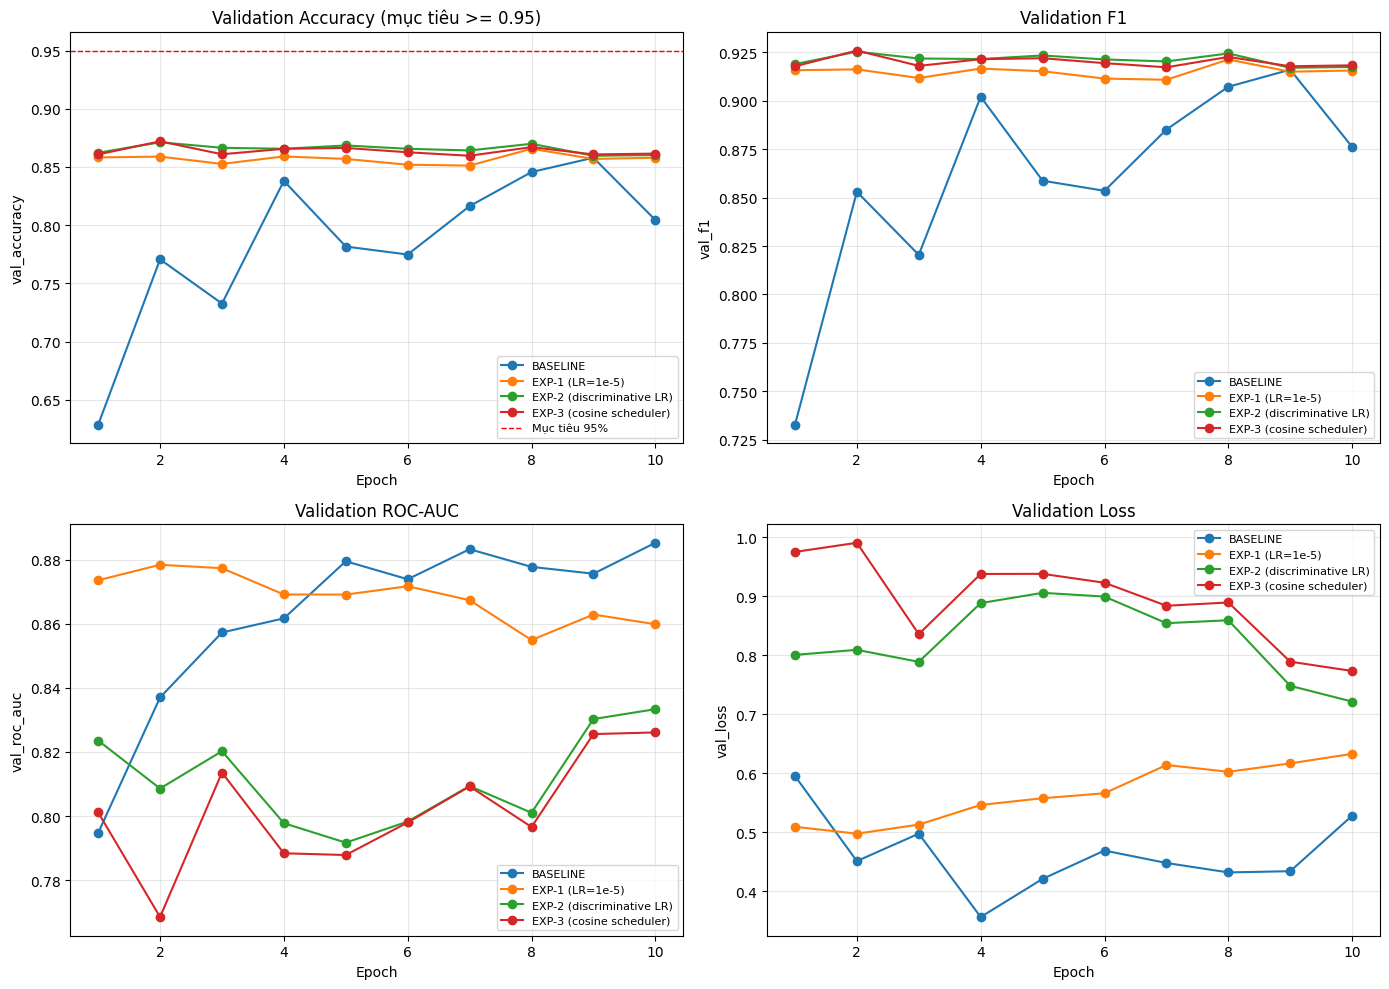

In [34]:
# =========================
# So sánh trực quan: BASELINE vs EXP-1 vs EXP-2 vs EXP-3
# (bổ sung Accuracy vì đây là mục tiêu chính của dự án >= 95%)
# =========================

baseline_history_path = os.path.join(
    EXPERIMENT_DIR, "histories", "convnext_tiny_history.csv"
)

exp1_history_path = os.path.join(
    FT_HISTORY_DIR, "convnext_tiny_exp1_lr_low_history.csv"
)

exp2_history_path = os.path.join(
    FT_HISTORY_DIR, "convnext_tiny_exp2_unfreeze_discriminative_lr_history.csv"
)

baseline_history = pd.read_csv(baseline_history_path)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

metrics_to_plot = [
    ("val_accuracy", "Validation Accuracy (mục tiêu >= 0.95)"),
    ("val_f1", "Validation F1"),
    ("val_roc_auc", "Validation ROC-AUC"),
    ("val_loss", "Validation Loss"),
]

for ax, (col, title) in zip(axes, metrics_to_plot):

    if col in baseline_history.columns:
        ax.plot(baseline_history["epoch"], baseline_history[col], marker="o", label="BASELINE")

    if os.path.exists(exp1_history_path):
        exp1_history = pd.read_csv(exp1_history_path)
        if col in exp1_history.columns:
            ax.plot(exp1_history["epoch"], exp1_history[col], marker="o", label="EXP-1 (LR=1e-5)")

    if os.path.exists(exp2_history_path):
        exp2_history = pd.read_csv(exp2_history_path)
        if col in exp2_history.columns:
            ax.plot(exp2_history["epoch"], exp2_history[col], marker="o", label="EXP-2 (discriminative LR)")

    ax.plot(exp3_history["epoch"], exp3_history[col], marker="o", label="EXP-3 (cosine scheduler)")

    if col == "val_accuracy":
        ax.axhline(0.95, color="red", linestyle="--", linewidth=1, label="Mục tiêu 95%")

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(col)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [35]:
print("EXP-3 hoàn tất.")
print()
print("Checkpoint của EXP-3         :", exp3_summary["checkpoint"])
print("Checkpoint TỐT NHẤT hiện tại (dùng cho EXP-4):", best_tracker["checkpoint"])
print()
print(f"Accuracy tốt nhất hiện tại: {best_tracker['best_val_accuracy']*100:.2f}%  (mục tiêu: 95%)")
print()
print("-> Notebook EXP-4 chỉ cần đọc lại best_tracker.json (cell 'Best tracker' ở trên)")
print("   để tự động fine-tune tiếp từ checkpoint tốt nhất tính đến thời điểm này.")
print()
print("Lưu ý: nếu ROC-AUC / val_loss vẫn xấu dần ở EXP-3 dù đã đổi scheduler,")
print("cân nhắc ở EXP-4 (Loss/regularization) thêm label smoothing, dropout,")
print("hoặc giảm nhẹ weight_decay/tăng regularization thay vì chỉ chỉnh LR schedule.")


EXP-3 hoàn tất.

Checkpoint của EXP-3         : /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth
Checkpoint TỐT NHẤT hiện tại (dùng cho EXP-4): /content/drive/MyDrive/FaceForensics_Experiments/finetune_convnext_tiny/checkpoints/convnext_tiny_exp3_cosine_scheduler_best.pth

Accuracy tốt nhất hiện tại: 87.20%  (mục tiêu: 95%)

-> Notebook EXP-4 chỉ cần đọc lại best_tracker.json (cell 'Best tracker' ở trên)
   để tự động fine-tune tiếp từ checkpoint tốt nhất tính đến thời điểm này.

Lưu ý: nếu ROC-AUC / val_loss vẫn xấu dần ở EXP-3 dù đã đổi scheduler,
cân nhắc ở EXP-4 (Loss/regularization) thêm label smoothing, dropout,
hoặc giảm nhẹ weight_decay/tăng regularization thay vì chỉ chỉnh LR schedule.
